# Text Processing with grep, sed & awk

Logs, CSV exports and configuration files are text. Three classic tools process text very fast, without writing a program:

- **grep** finds lines that match a pattern,
- **sed** edits text line by line (search and replace),
- **awk** splits lines into fields and computes on them.

**After this lesson you can:**

1. Write regular expressions for `grep -E`.
2. Replace and delete text with `sed`.
3. Filter, aggregate and format columns with `awk`.
4. Analyse a real system log with a pipeline.

The real data in this lesson is the package log of this machine, `/var/log/dpkg.log`.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

WORK = Path(tempfile.mkdtemp())          # a folder on the Linux file system (not on a Windows drive)
REPO = Path.cwd().parent                 # the course repository: real data for some examples

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def sh(cmd: str, cwd: Path = WORK, quiet: bool = False, check: bool = False) -> Output:
    """Run a command with bash, print the command and its output."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True)
    shorten = lambda t: t.replace(str(WORK), "<work>").replace(str(REPO), "<repo>")
    out = shorten((r.stdout + r.stderr).rstrip())
    if not quiet:
        print(f"$ {shorten(cmd)}" + (f"\n{out}" if out else ""))
    if check and r.returncode:
        raise RuntimeError(f"command failed with exit code {r.returncode}")
    return Output(r.stdout)

## 1. Regular Expressions and grep

A **regular expression** (regex) describes a set of strings.

| Pattern | Matches |
| :--- | :--- |
| `.` | any character |
| `[0-9]`, `[a-z]` | one character from a set |
| `^` / `$` | start / end of the line |
| `*`, `+`, `?` | 0 or more, 1 or more, 0 or 1 of the previous item |
| `{3}`, `{2,5}` | exactly 3, between 2 and 5 repetitions |
| `(a\|b)` | `a` or `b` |

Useful grep options: `-E` extended regex, `-i` ignore case, `-v` invert, `-c` count, `-o` print only the match, `-n` line numbers.

In [2]:
log = Path("/var/log/dpkg.log")
if not log.exists():                                        # other systems: use a small sample with the same format
    log = WORK / "dpkg.log"
    log.write_text("2025-01-02 10:00:01 install python3:amd64 <none> 3.12.3\n"
                   "2025-01-02 10:00:05 status installed python3:amd64 3.12.3\n"
                   "2025-01-03 09:12:44 upgrade curl:amd64 7.81.0 7.81.1\n")
LOG = str(log)
sh(f"wc -l {LOG} && head -3 {LOG}")
sh(f"grep -c ' install ' {LOG}")
sh(f"grep -E ' (install|upgrade) ' {LOG} | head -4")
sh(f"grep -oE ' install [a-z0-9.+-]+' {LOG} | head -5")

$ wc -l /var/log/dpkg.log && head -3 /var/log/dpkg.log
534 /var/log/dpkg.log
2026-11-01 21:00:04 startup archives unpack
2026-11-01 21:00:24 install openjdk-21-jre-headless:amd64 <none> 21.0.12.1+1-1~22.04.4
2026-11-01 21:00:24 status half-installed openjdk-21-jre-headless:amd64 21.0.12.1+1-1~22.04.4
$ grep -c ' install ' /var/log/dpkg.log
2
$ grep -E ' (install|upgrade) ' /var/log/dpkg.log | head -4
2026-11-01 21:00:24 install openjdk-21-jre-headless:amd64 <none> 21.0.12.1+1-1~22.04.4
2026-11-01 21:00:34 install openjdk-21-jdk-headless:amd64 <none> 21.0.12.1+1-1~22.04.4
2026-11-02 13:16:19 upgrade linux-libc-dev:amd64 5.15.0-198.208 5.15.0-202.212
2026-11-08 14:19:21 upgrade libapt-pkg6.0:amd64 2.4.13 2.4.15ubuntu0.1
$ grep -oE ' install [a-z0-9.+-]+' /var/log/dpkg.log | head -5
 install openjdk-21-jre-headless
 install openjdk-21-jdk-headless


## 2. sed: Stream Editing

`sed 's/old/new/g'` replaces every match of `old` with `new` on each line. `-E` enables extended regex, and `\1` refers to the first group in brackets. `sed -n '5,10p'` prints lines 5–10; `sed '/pattern/d'` deletes matching lines. `sed -i` edits a file in place (careful: no undo).

In [3]:
sh(f"head -3 {LOG} | sed -E 's/([0-9]{{4}})-([0-9]{{2}})-([0-9]{{2}})/\\3.\\2.\\1/'")    # reorder the date
sh(f"grep ' install ' {LOG} | head -3 | sed -E 's/:amd64//; s/<none> //'")             # remove noise
(WORK / "app.conf").write_text("host=localhost\nport=5432\ndebug=true\n# old setting\ntimeout=30\n")
sh("sed -i 's/^debug=true/debug=false/; /^#/d' app.conf && cat app.conf")

$ head -3 /var/log/dpkg.log | sed -E 's/([0-9]{4})-([0-9]{2})-([0-9]{2})/\3.\2.\1/'
01.11.2026 21:00:04 startup archives unpack
01.11.2026 21:00:24 install openjdk-21-jre-headless:amd64 <none> 21.0.12.1+1-1~22.04.4
01.11.2026 21:00:24 status half-installed openjdk-21-jre-headless:amd64 21.0.12.1+1-1~22.04.4
$ grep ' install ' /var/log/dpkg.log | head -3 | sed -E 's/:amd64//; s/<none> //'
2026-11-01 21:00:24 install openjdk-21-jre-headless 21.0.12.1+1-1~22.04.4
2026-11-01 21:00:34 install openjdk-21-jdk-headless 21.0.12.1+1-1~22.04.4
$ sed -i 's/^debug=true/debug=false/; /^#/d' app.conf && cat app.conf
host=localhost
port=5432
debug=false
timeout=30


## 3. awk: Fields and Calculations

awk splits each line into fields: `$1`, `$2`, ... (`$0` is the whole line, `NF` the number of fields). A program has the form `pattern { action }`. The `BEGIN` block runs before the first line, `END` after the last line. awk has associative arrays, so it can count and sum per key.

In [4]:
sh(f"awk '$3 == \"install\" {{ print $1, $4 }}' {LOG} | head -4")                    # filter + select
sh(f"awk '{{ actions[$3]++ }} END {{ for (a in actions) print actions[a], a }}' {LOG} | sort -rn | head -6")
daily = sh(f"awk '$3 == \"install\" || $3 == \"upgrade\" {{ n[$1]++ }} END {{ for (d in n) print d, n[d] }}' {LOG} | sort")

$ awk '$3 == "install" { print $1, $4 }' /var/log/dpkg.log | head -4
2026-11-01 openjdk-21-jre-headless:amd64
2026-11-01 openjdk-21-jdk-headless:amd64
$ awk '{ actions[$3]++ } END { for (a in actions) print actions[a], a }' /var/log/dpkg.log | sort -rn | head -6
370 status
55 startup
43 configure
41 upgrade
23 trigproc
2 install
$ awk '$3 == "install" || $3 == "upgrade" { n[$1]++ } END { for (d in n) print d, n[d] }' /var/log/dpkg.log | sort
2026-11-01 2
2026-11-02 1
2026-11-08 10
2026-11-09 2
2026-11-11 18
2026-11-13 2
2026-11-16 8


## 4. A Real Analysis: Package Activity on This Machine

The awk command above counted installs and upgrades per day. The plot shows the result. On a server, the same three tools answer questions such as "which IP addresses caused the most errors in the last hour?".

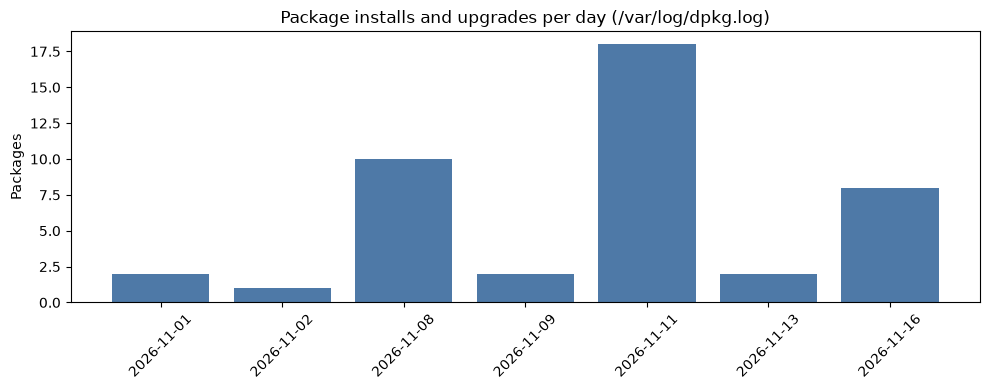

packages upgraded (count of upgrades):
      2 linux-libc-dev
      2 ca-certificates-java
      1 python3-twisted
      1 python3-pyasn1
      1 perl-modules-5.34



In [5]:
import matplotlib.pyplot as plt

rows = [line.split() for line in daily.splitlines() if line.strip()]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([d for d, _ in rows], [int(n) for _, n in rows], color="#4E79A7")
ax.set(title=f"Package installs and upgrades per day ({log})", ylabel="Packages")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
top = sh(f"awk '$3 == \"upgrade\" {{ print $4 }}' {LOG} | sed 's/:.*//' | sort | uniq -c | sort -rn | head -5", quiet=True)
print("packages upgraded (count of upgrades):\n" + top)

## 5. When to Use Which Tool

| Task | Tool |
| :--- | :--- |
| find lines, count matches | `grep` (or `rg`, ripgrep, for large code bases) |
| replace text, delete lines | `sed` |
| work with columns, sums, counts per key | `awk` |
| CSV with quotes, joins, real statistics | Python/pandas, DuckDB (M07, M08) |
| JSON | `jq` (Lesson 05) |

*Insight: For a quick question about a text file, a one-line grep/sed/awk pipeline is often faster than opening a notebook. When the logic needs more than one line of awk, switch to Python: readable code is more important than a clever one-liner.*

## Real-World Use Case or Analogy

grep, sed and awk are like the **highlighter, eraser and calculator** of a person who reads printed reports: highlight the interesting lines, cross out or rewrite words, and add up a column at the margin.

On-call engineers use them on production servers that have no Python data stack installed: find the error that appeared after a deployment, count failed logins per IP address, or rewrite a configuration value in a hundred files with one `sed` command.